# Klasyfikacja stanu zdrowia płodu na podstawie kardiotokografii
## Fetal Health Classification

**Opis:** Projekt klasyfikacji wieloklasowej (Normal / Suspect / Pathological) na podstawie 2126 rekordów pomiarów kardiotokograficznych (CTG). Modele: Random Forest + XGBoost.

**Zbiór danych:** [Kaggle – Fetal Health Classification](https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification)

## 1. Konfiguracja i import bibliotek

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

class ShiftedLabelXGBClassifier(XGBClassifier):
    def fit(self, X, y, **kwargs):
        return super().fit(X, np.asarray(y).astype(int) - 1, **kwargs)

    def predict(self, X, **kwargs):
        return super().predict(X, **kwargs) + 1

print("Biblioteki załadowane pomyślnie.")

Biblioteki załadowane pomyślnie.


## 2. Wczytanie danych i wstępna eksploracja

In [11]:
df = pd.read_csv('fetal_health.csv')
print(f"Wymiary zbioru: {df.shape[0]} rekordów, {df.shape[1]} kolumn")
df.head()

Wymiary zbioru: 2126 rekordów, 22 kolumn


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
baseline value,2126.0,133.303857,9.840844,106.0,126.000,133.000,140.000,160.000
accelerations,2126.0,0.003178,0.003866,0.0,0.000,0.002,0.006,0.019
fetal_movement,2126.0,0.009481,0.046666,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2126.0,0.004366,0.002946,0.0,0.002,0.004,0.007,0.015
light_decelerations,2126.0,0.001889,0.002960,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2126.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2126.0,0.000159,0.000590,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2126.0,46.990122,17.192814,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2126.0,1.332785,0.883241,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2126.0,9.846660,18.396880,0.0,0.000,0.000,11.000,91.000


### Podstawowe statystyki opisowe cech

In [45]:
feature_cols = df.select_dtypes(include='number').columns.drop('fetal_health')

stats = pd.DataFrame({
    'Średnia': df[feature_cols].mean(),
    'Mediana': df[feature_cols].median(),
    'Odch. std.': df[feature_cols].std(),
    'Min': df[feature_cols].min(),
    'Max': df[feature_cols].max(),
    'Skośność': df[feature_cols].skew(),
    'Kurtoza': df[feature_cols].kurtosis()
}).round(2)

stats

,Średnia,Mediana,Odch. std.,Min,Max,Skośność,Kurtoza
baseline_value,133.30,133.0,9.84,106.0,160.00,0.02,-0.29
accelerations,0.00,0.0,0.00,0.0,0.02,1.20,0.77
fetal_movement,0.01,0.0,0.05,0.0,0.48,7.81,64.26
uterine_contractions,0.00,0.0,0.00,0.0,0.02,0.16,-0.64
light_decelerations,0.00,0.0,0.00,0.0,0.02,1.72,2.52
severe_decelerations,0.00,0.0,0.00,0.0,0.00,17.35,299.42
prolongued_decelerations,0.00,0.0,0.00,0.0,0.00,4.32,20.52
abnormal_short_term_variability,46.99,49.0,17.19,12.0,87.00,-0.01,-1.05
mean_value_of_short_term_variability,1.33,1.2,0.88,0.2,7.00,1.66,4.70
percentage_of_time_with_abnormal_long_term_variability,9.85,0.0,18.40,0.0,91.00,2.20,4.25


In [42]:
print(f"Brakujące wartości: {df.isnull().sum().sum()} (łącznie)")
print(f"Duplikaty: {df.duplicated().sum()} rekordów")

Brakujące wartości: 0 (łącznie)
Duplikaty: 13 rekordów


13 duplikatów stanowi około 0.6% zbioru — mogą być rzeczywistymi powtórzeniami pomiarów CTG, dlatego zostały pozostawione w zbiorze.

Rozkład klas:
  1 (Normal): 1655 (77.8%)
  2 (Suspect): 295 (13.9%)
  3 (Pathological): 176 (8.3%)


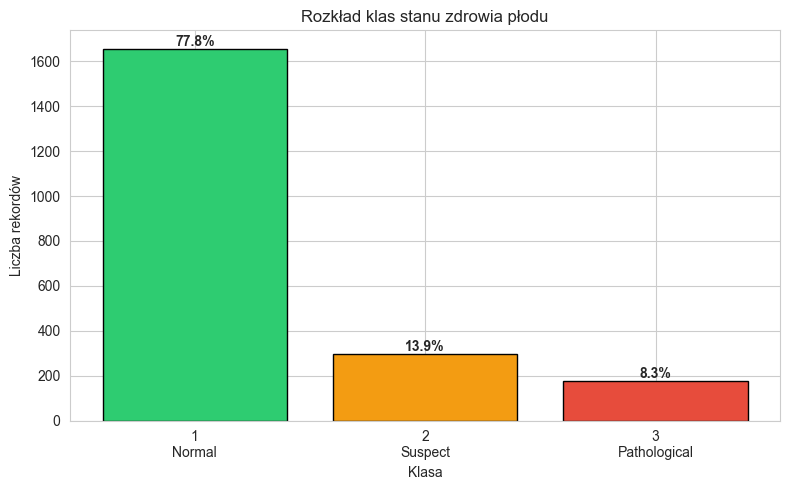

In [43]:
class_labels = {1.0: 'Normal', 2.0: 'Suspect', 3.0: 'Pathological'}
class_counts = df['fetal_health'].value_counts().sort_index()
class_pct = df['fetal_health'].value_counts(normalize=True).sort_index() * 100

print("Rozkład klas:")
for cls in class_counts.index:
    print(f"  {int(cls)} ({class_labels[cls]}): {class_counts[cls]} ({class_pct[cls]:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2ecc71', '#f39c12', '#e74c3c']
bars = ax.bar([f"{int(k)}\n{v}" for k, v in class_labels.items()], class_counts.values, color=colors, edgecolor='black')
for bar, pct in zip(bars, class_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15, f"{pct:.1f}%", ha='center', fontweight='bold')
ax.set_xlabel('Klasa')
ax.set_ylabel('Liczba rekordów')
ax.set_title('Rozkład klas stanu zdrowia płodu')
plt.tight_layout()
plt.show()

## 3. Analiza eksploracyjna (EDA) — wizualizacje

### Histogramy rozkładów cech

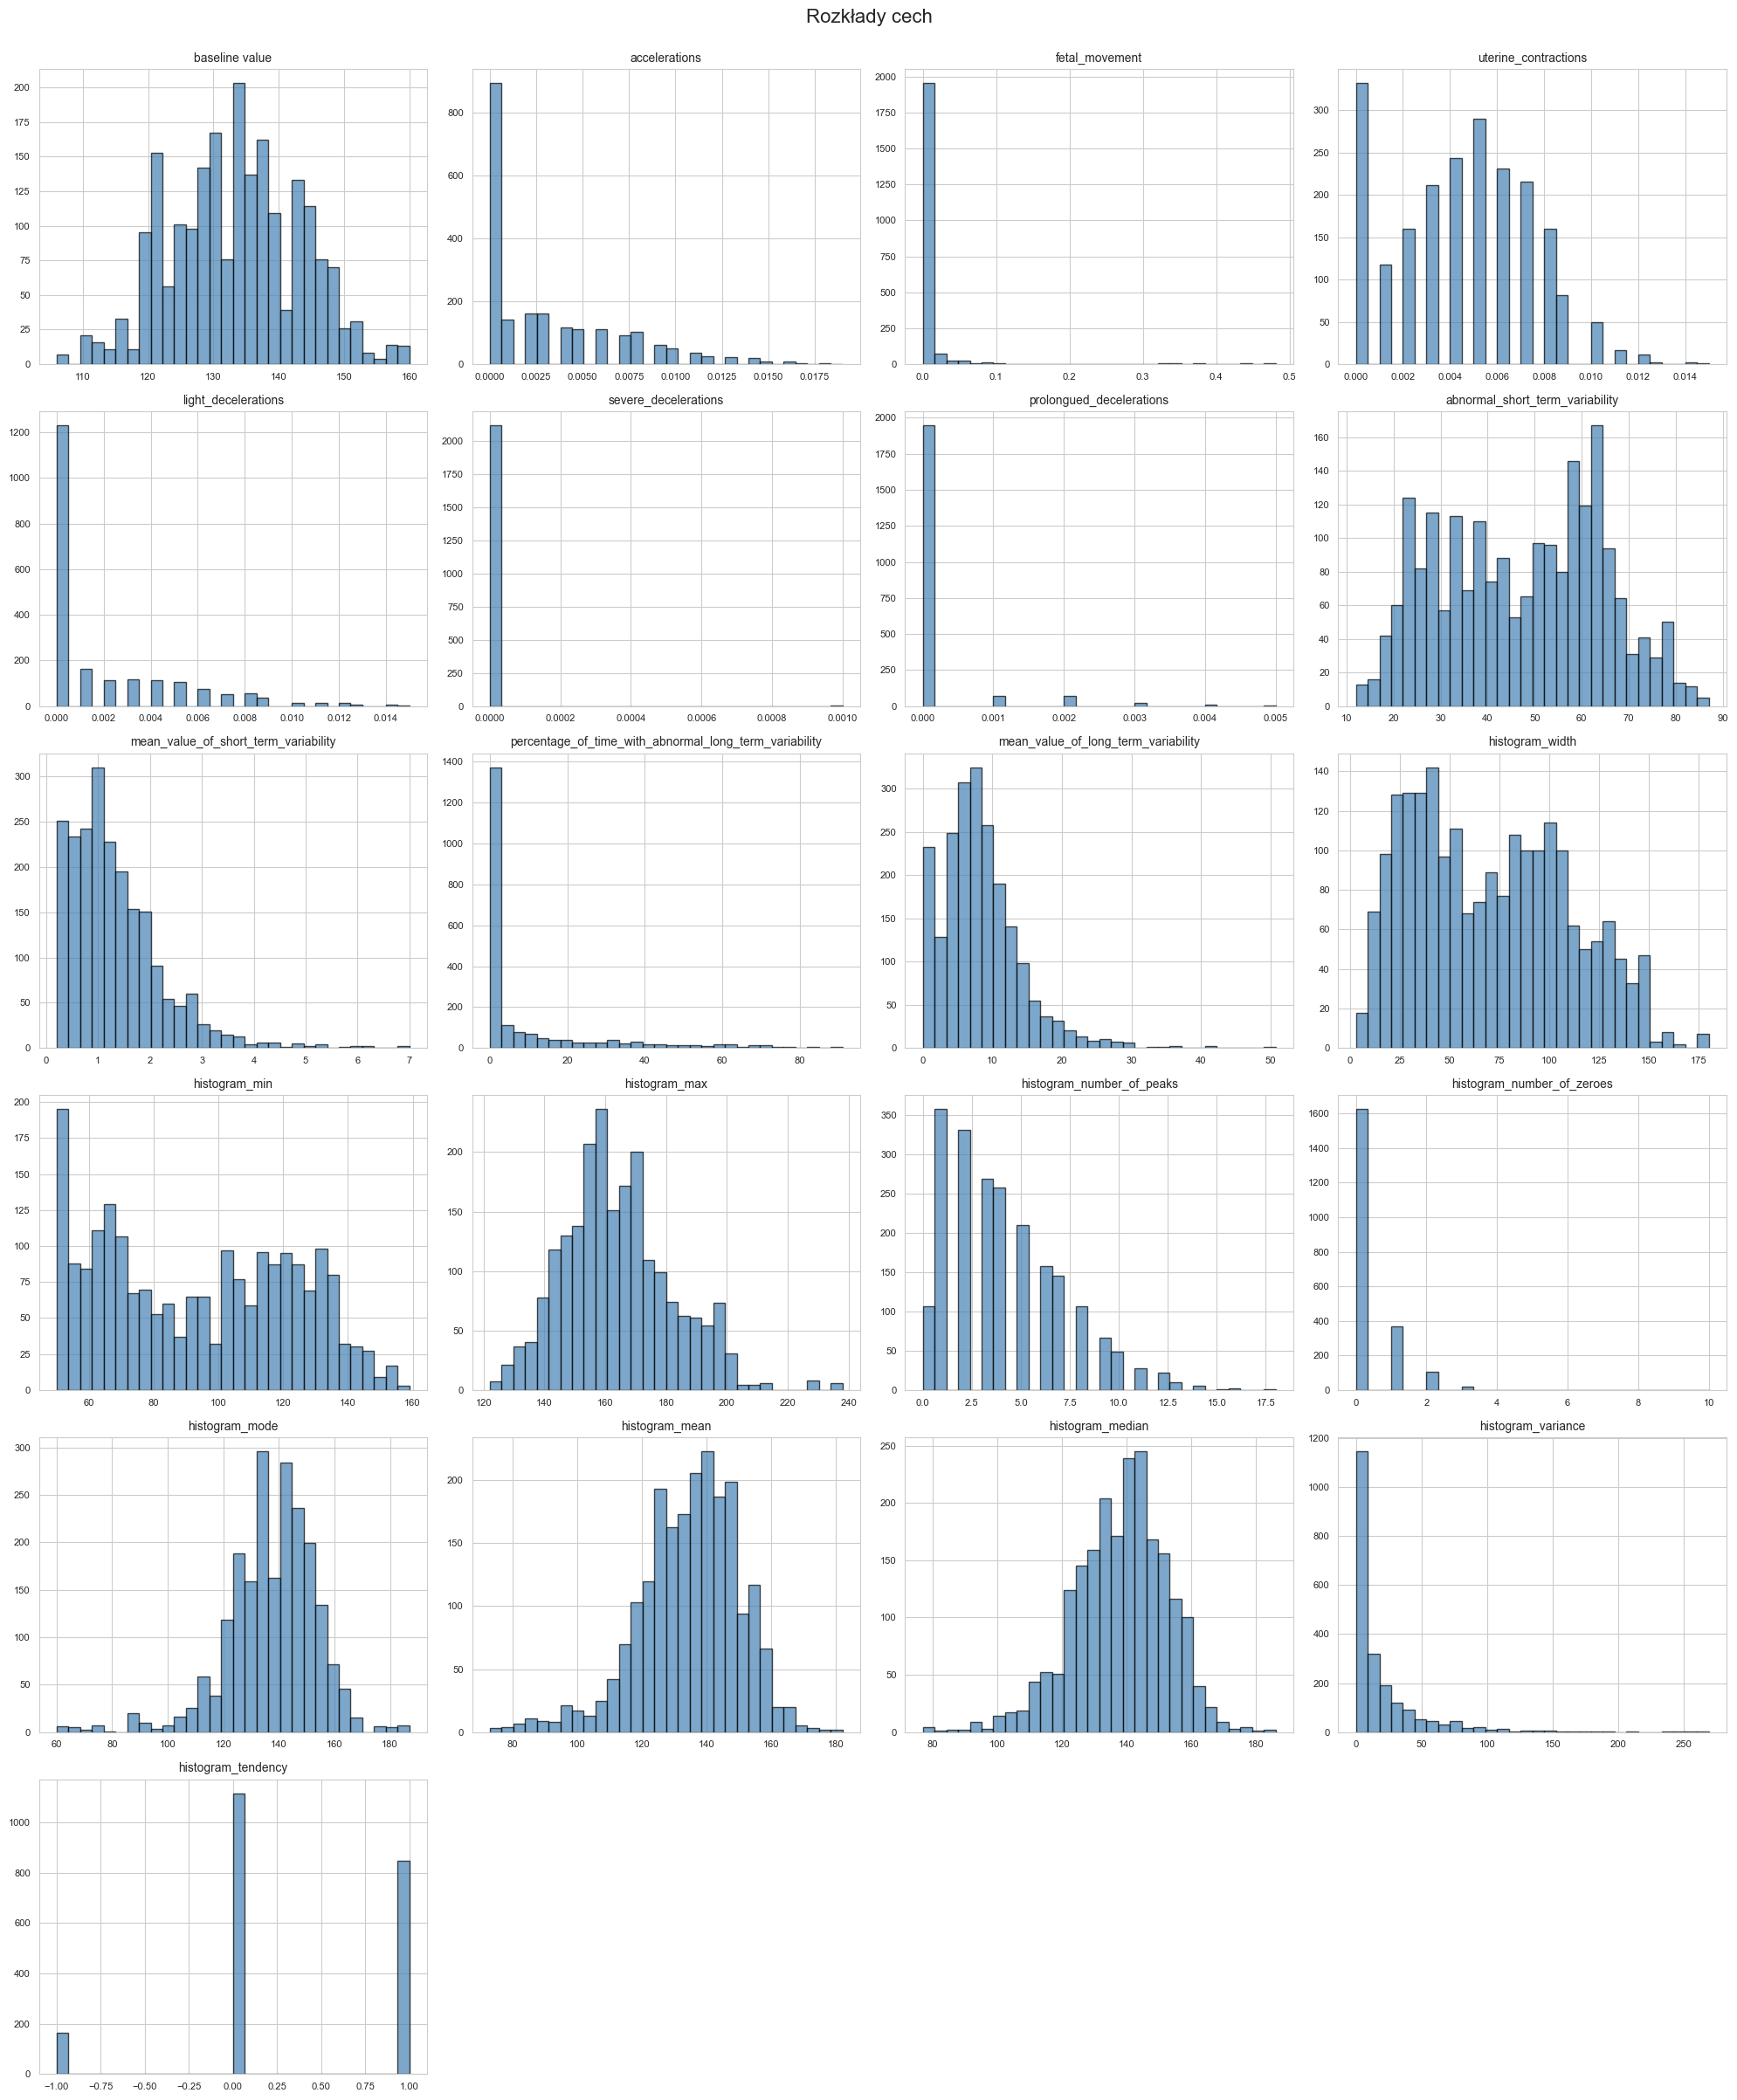

In [16]:
features = df.columns.drop('fetal_health')

fig, axes = plt.subplots(nrows=6, ncols=4, figsize=(20, 24))
axes = axes.flatten()

for i, col in enumerate(features):
    df[col].hist(ax=axes[i], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(labelsize=8)

for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Rozkłady cech', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

### Macierz korelacji

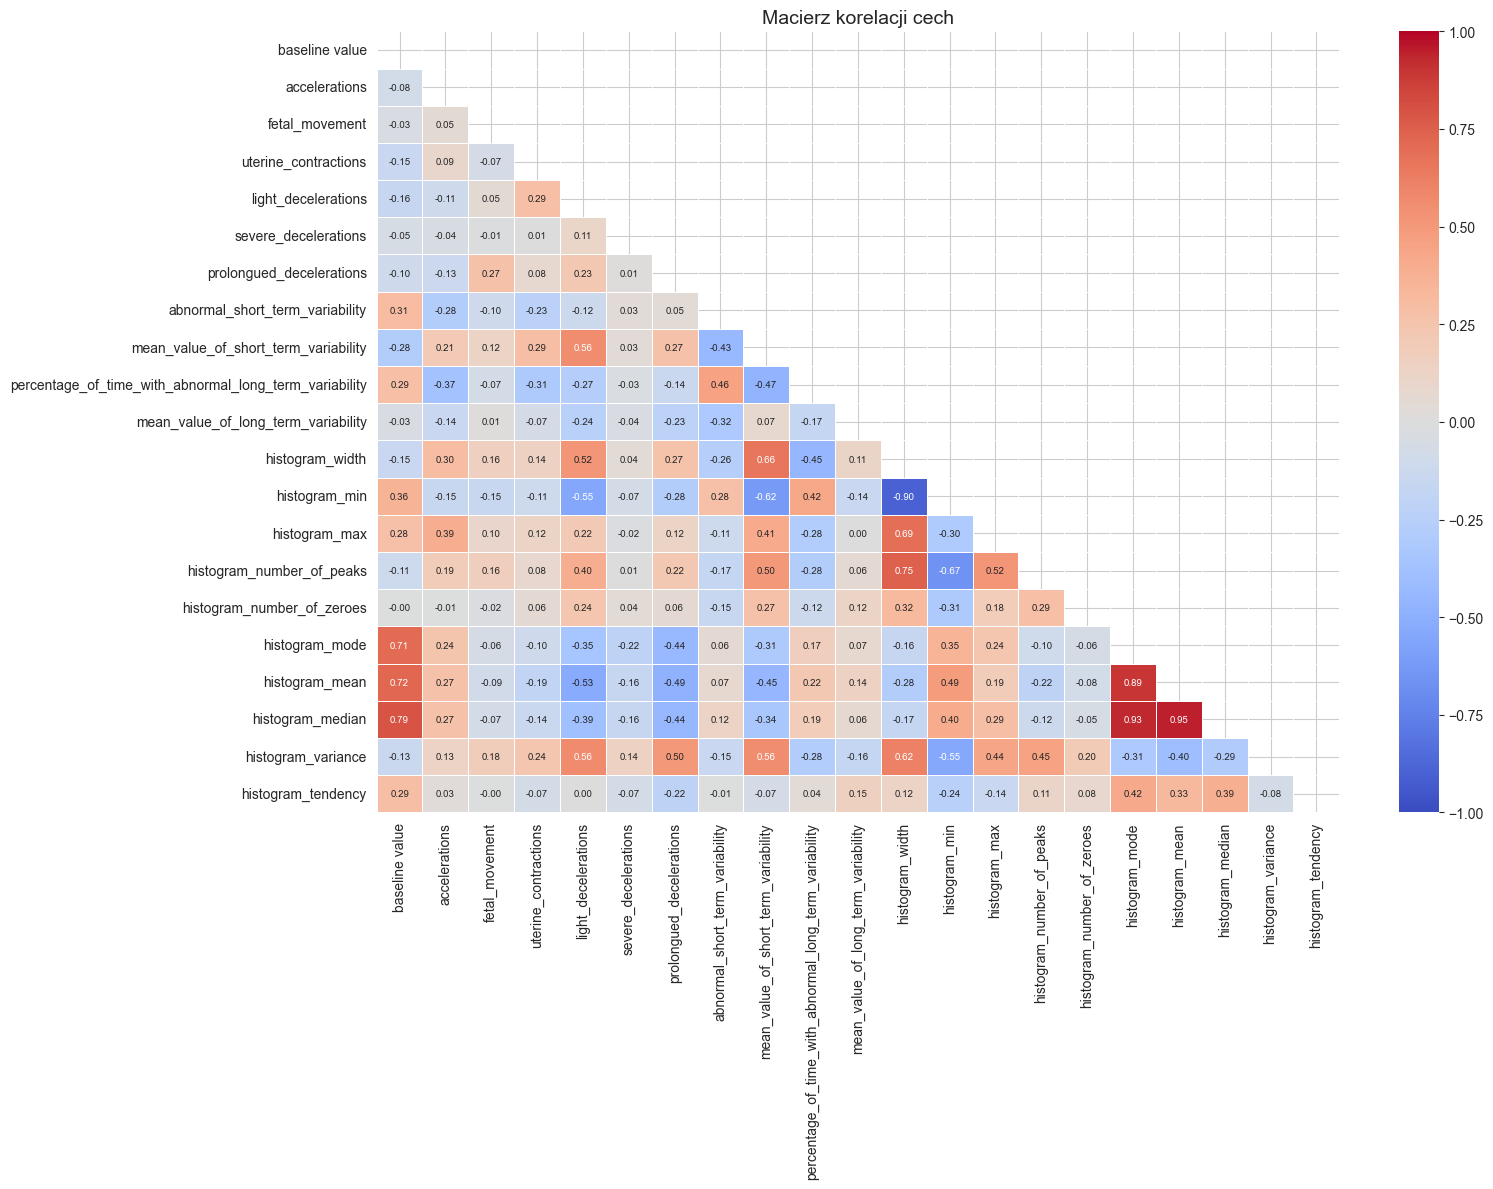


Pary cech z korelacją > 0.85:
  histogram_width <-> histogram_min: -0.899
  histogram_mode <-> histogram_mean: 0.893
  histogram_mode <-> histogram_median: 0.933
  histogram_mean <-> histogram_median: 0.948


In [17]:
corr_matrix = df.drop(columns='fetal_health').corr()

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size': 7},
            vmin=-1, vmax=1)
ax.set_title('Macierz korelacji cech', fontsize=14)
plt.tight_layout()
plt.show()

high_corr_threshold = 0.85
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > high_corr_threshold:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

print(f"\nPary cech z korelacją > {high_corr_threshold}:")
for c1, c2, val in high_corr_pairs:
    print(f"  {c1} <-> {c2}: {val:.3f}")

### Boxploty wybranych cech w podziale na klasy

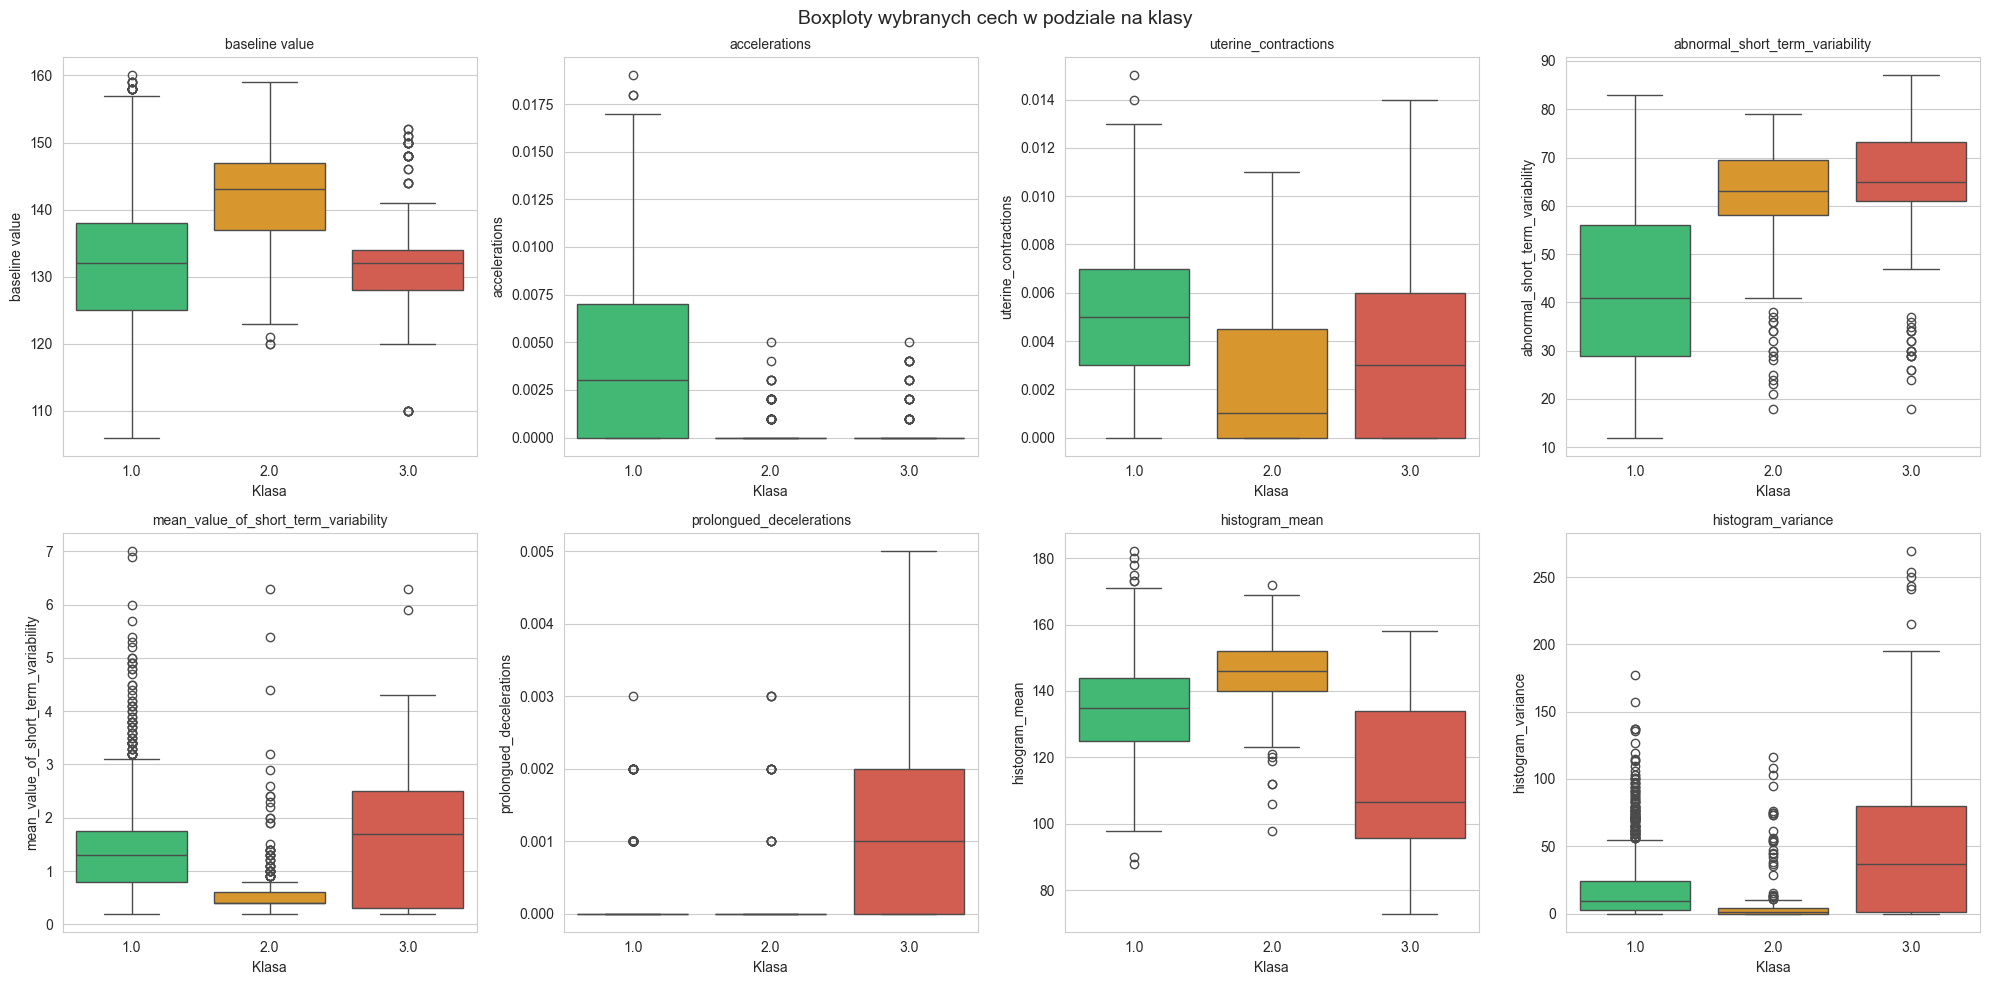

In [18]:
selected_features = [
    'baseline value', 'accelerations', 'uterine_contractions',
    'abnormal_short_term_variability', 'mean_value_of_short_term_variability',
    'prolongued_decelerations', 'histogram_mean', 'histogram_variance'
]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axes = axes.flatten()

palette = {1.0: '#2ecc71', 2.0: '#f39c12', 3.0: '#e74c3c'}

for i, col in enumerate(selected_features):
    sns.boxplot(data=df, x='fetal_health', y=col, hue='fetal_health',
                ax=axes[i], palette=palette, legend=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Klasa')

fig.suptitle('Boxploty wybranych cech w podziale na klasy', fontsize=14)
plt.tight_layout()
plt.show()

### Pairplot (top 6 cech)

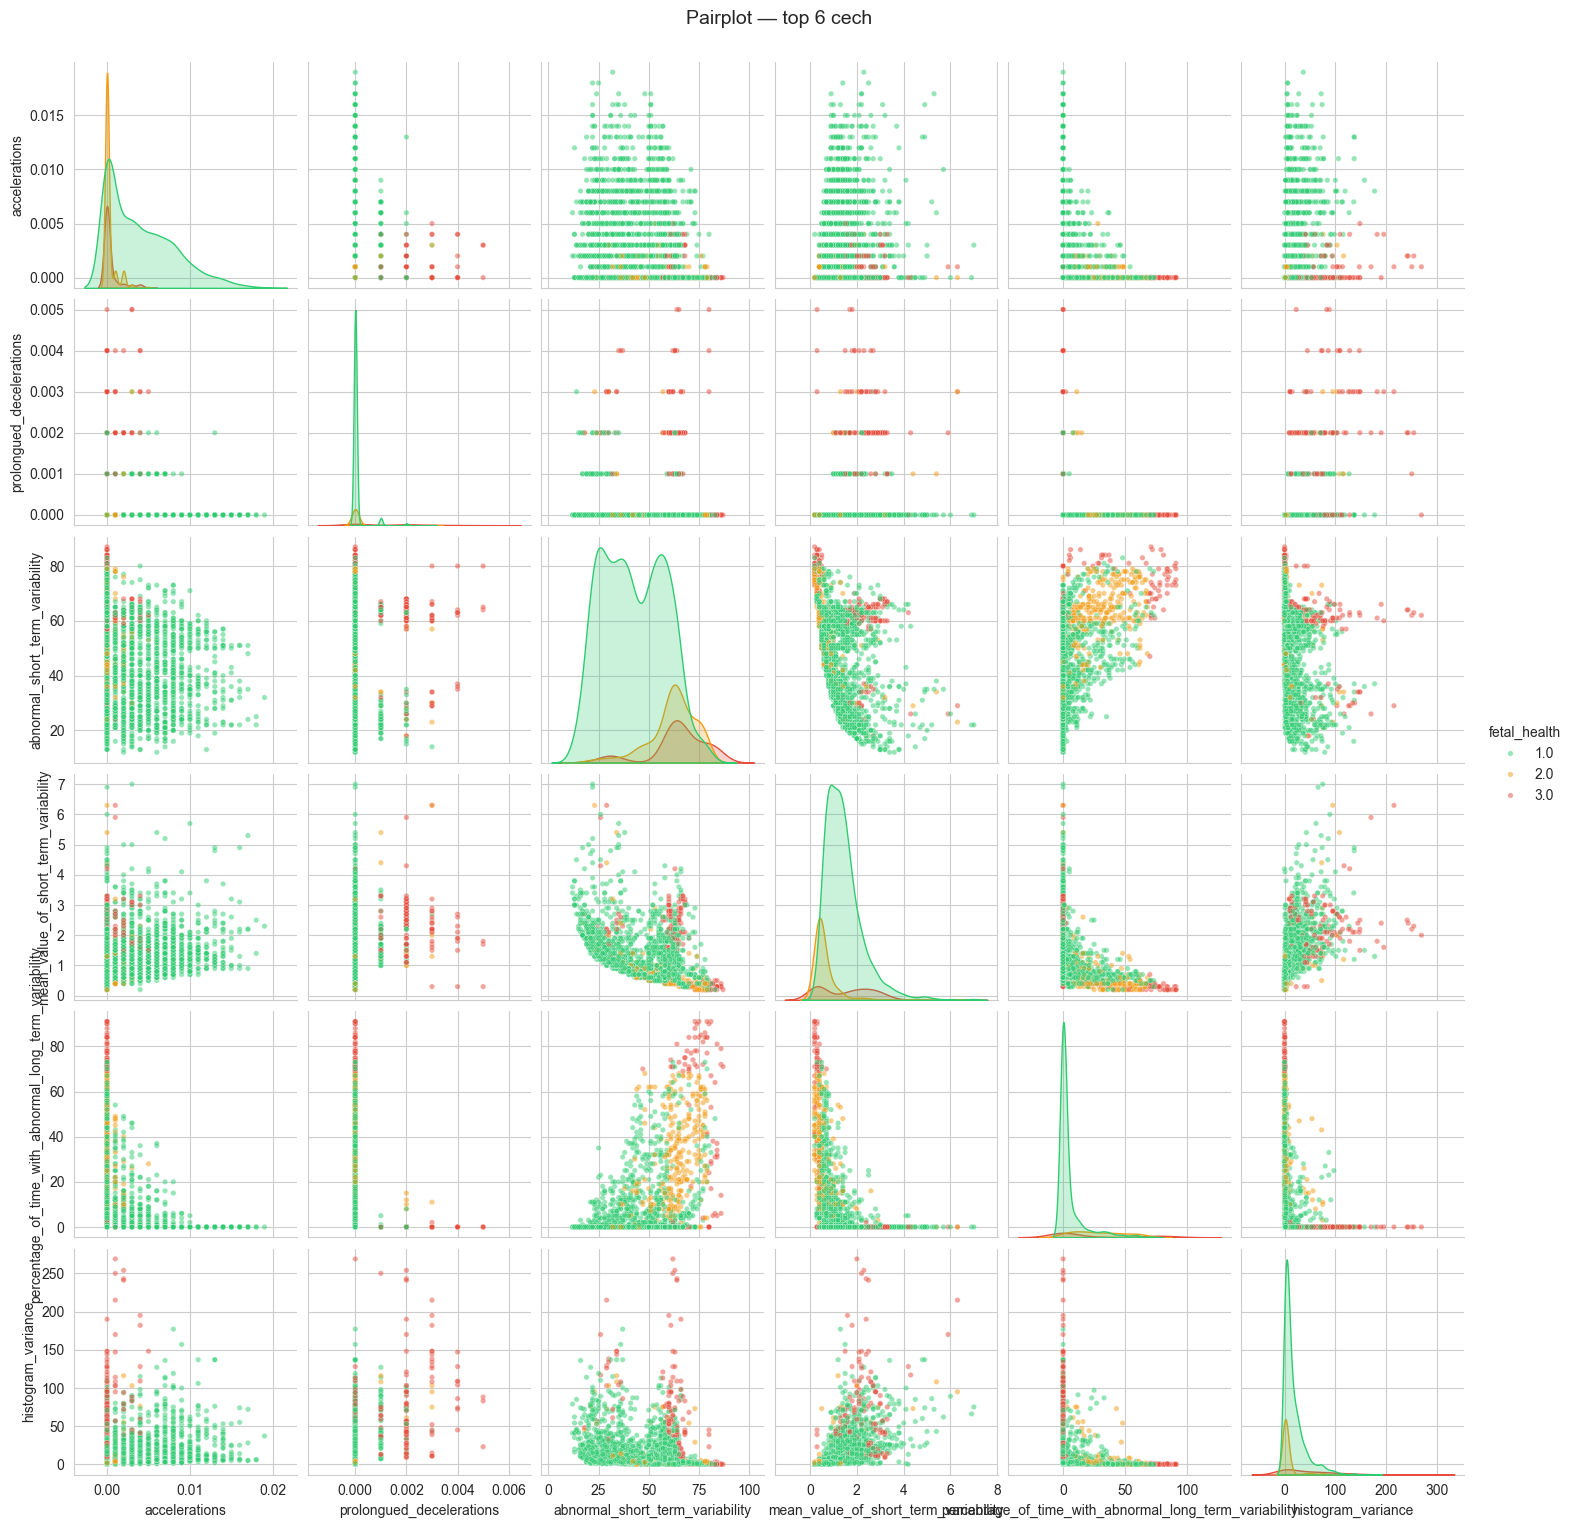

In [19]:
pairplot_cols = [
    'accelerations', 'prolongued_decelerations',
    'abnormal_short_term_variability', 'mean_value_of_short_term_variability',
    'percentage_of_time_with_abnormal_long_term_variability', 'histogram_variance',
    'fetal_health'
]

g = sns.pairplot(df[pairplot_cols], hue='fetal_health',
                 palette={1.0: '#2ecc71', 2.0: '#f39c12', 3.0: '#e74c3c'},
                 diag_kind='kde', plot_kws={'alpha': 0.5, 's': 15})
g.figure.suptitle('Pairplot — top 6 cech', y=1.02, fontsize=14)
plt.show()

## 4. Preprocessing

### Ujednolicenie nazw kolumn i podział na cechy / zmienną docelową

In [20]:
df.columns = df.columns.str.replace(' ', '_')
print("Kolumny po ujednoliceniu:")
print(df.columns.tolist())

X = df.drop(columns='fetal_health')
y = df['fetal_health'].astype(int)

print(f"\nX: {X.shape}, y: {y.shape}")
print(f"Klasy w y: {sorted(y.unique())}")

Kolumny po ujednoliceniu:
['baseline_value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_min', 'histogram_max', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean', 'histogram_median', 'histogram_variance', 'histogram_tendency', 'fetal_health']

X: (2126, 21), y: (2126,)
Klasy w y: [np.int64(1), np.int64(2), np.int64(3)]


### Podział train/test i selekcja cech — usunięcie silnie skorelowanych (próg > 0.85)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} rekordów, Test: {X_test.shape[0]} rekordów")
print(f"Rozkład klas w train:\n{y_train.value_counts().sort_index()}")
print(f"\nRozkład klas w test:\n{y_test.value_counts().sort_index()}")

corr_train = X_train.corr().abs()
upper = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] > 0.85)]
print(f"\nCechy do usunięcia (korelacja > 0.85, liczona na train): {to_drop}")

X_train_selected = X_train.drop(columns=to_drop)
X_test_selected = X_test.drop(columns=to_drop)

print(f"Pozostałe cechy ({X_train_selected.shape[1]}): {X_train_selected.columns.tolist()}")

Cechy do usunięcia (korelacja > 0.85): ['histogram_min', 'histogram_mean', 'histogram_median']
Pozostałe cechy (18): ['baseline_value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_max', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_mode', 'histogram_variance', 'histogram_tendency']


### Brak standaryzacji dla modeli drzewiastych i podgląd wpływu SMOTE

In [ ]:
print(f"Liczba cech przed selekcją: {X_train.shape[1]}")
print(f"Liczba cech po selekcji:    {X_train_selected.shape[1]}")

print("\nModele drzewiaste nie wymagają standaryzacji, dlatego dalsze modelowanie wykonujemy na surowych cechach po selekcji korelacyjnej.")
print(f"Kształt X_train_selected: {X_train_selected.shape}")
print(f"Kształt X_test_selected:  {X_test_selected.shape}")

Train: 1700 rekordów, Test: 426 rekordów
Rozkład klas w train:
fetal_health
1    1323
2     236
3     141
Name: count, dtype: int64

Rozkład klas w test:
fetal_health
1    332
2     59
3     35
Name: count, dtype: int64


In [ ]:
smote_preview = SMOTE(random_state=RANDOM_STATE)
_, y_train_sm_preview = smote_preview.fit_resample(X_train_selected, y_train)

y_train_sm_preview = pd.Series(y_train_sm_preview, name='fetal_health')

print(f"Przed SMOTE: {X_train_selected.shape[0]} rekordów")
print(f"Po SMOTE (podgląd): {len(y_train_sm_preview)} rekordów")
print(f"\nRozkład klas po SMOTE:\n{y_train_sm_preview.value_counts().sort_index()}")
print("\nWłaściwe treningi modeli użyją SMOTE wewnątrz pipeline, dzięki czemu nie ma wycieku danych do cross-validacji.")

Standaryzacja zakończona.
Średnie cech w train (powinny być ~0): -0.000000
Odch. std. cech w train (powinny być ~1): 1.000294


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Skonfigurowano stratyfikowaną cross-validację: {cv.get_n_splits()} foldów")

Przed SMOTE: 1700 rekordów
Po SMOTE:    3969 rekordów

Rozkład klas po SMOTE:
fetal_health
1    1323
2    1323
3    1323
Name: count, dtype: int64


## 5. Model 1: Random Forest

### Trening z domyślnymi parametrami

In [ ]:
rf_base = Pipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

rf_base.fit(X_train_selected, y_train)

y_pred_rf_base = rf_base.predict(X_test_selected)
print("Random Forest — domyślne parametry:")
print(f"  Accuracy:      {accuracy_score(y_test, y_pred_rf_base):.4f}")
print(f"  F1 (macro):    {f1_score(y_test, y_pred_rf_base, average='macro'):.4f}")

Random Forest — domyślne parametry:
  Accuracy:      0.9319
  F1 (macro):    0.8768


### GridSearchCV — tuning hiperparametrów

In [ ]:
rf_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

rf_grid = GridSearchCV(
    Pipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_selected, y_train)

best_rf_params = {k.replace('model__', ''): v for k, v in rf_grid.best_params_.items()}
print(f"\nNajlepsze parametry: {best_rf_params}")
print(f"Najlepszy F1 (macro) z CV: {rf_grid.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Najlepsze parametry: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Najlepszy F1 (macro) z CV: 0.9771


In [ ]:
rf_best = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test_selected)

print("Random Forest — najlepszy model (po GridSearch):")
print(f"  Accuracy:      {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"  F1 (macro):    {f1_score(y_test, y_pred_rf, average='macro'):.4f}")

Random Forest — najlepszy model (po GridSearch):
  Accuracy:      0.9319
  F1 (macro):    0.8768


### Feature importance — Random Forest

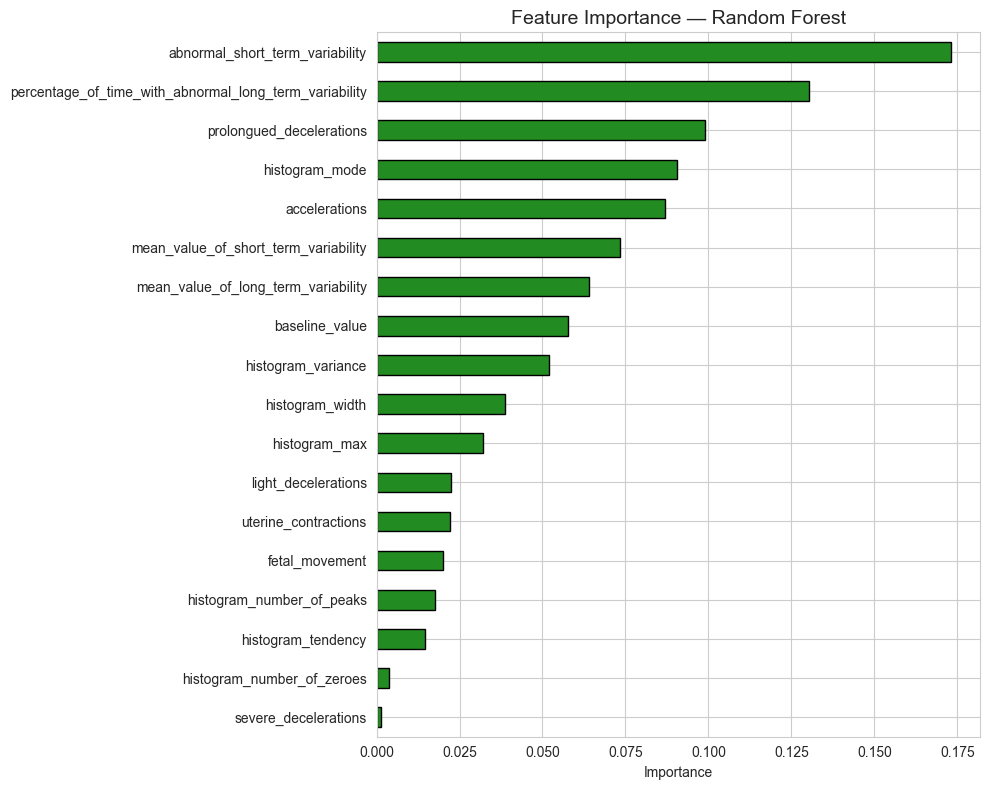


Top 5 najważniejszych cech (RF):
  abnormal_short_term_variability: 0.1732
  percentage_of_time_with_abnormal_long_term_variability: 0.1303
  prolongued_decelerations: 0.0988
  histogram_mode: 0.0907
  accelerations: 0.0870


In [ ]:
importances_rf = rf_best.named_steps['model'].feature_importances_
feat_imp_rf = pd.Series(importances_rf, index=X_train_selected.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
feat_imp_rf.plot(kind='barh', ax=ax, color='forestgreen', edgecolor='black')
ax.set_title('Feature Importance — Random Forest', fontsize=14)
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nTop 5 najważniejszych cech (RF):")
for feat, imp in feat_imp_rf.sort_values(ascending=False).head(5).items():
    print(f"  {feat}: {imp:.4f}")

## 6. Model 2: XGBoost (Gradient Boosting)

### Trening z domyślnymi parametrami

> **Uwaga:** XGBoost wymaga klas zaczynających się od 0, dlatego wewnętrznie przesuwamy etykiety o -1 przy treningu i +1 przy predykcji. Na zewnątrz nadal operujemy na oryginalnych klasach 1/2/3.

In [ ]:
xgb_base = Pipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', ShiftedLabelXGBClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        eval_metric='mlogloss'
    ))
])

xgb_base.fit(X_train_selected, y_train)

y_pred_xgb_base = xgb_base.predict(X_test_selected)
print("XGBoost — domyślne parametry:")
print(f"  Accuracy:      {accuracy_score(y_test, y_pred_xgb_base):.4f}")
print(f"  F1 (macro):    {f1_score(y_test, y_pred_xgb_base, average='macro'):.4f}")

XGBoost — domyślne parametry:
  Accuracy:      0.9413
  F1 (macro):    0.8828


### GridSearchCV — tuning hiperparametrów

In [ ]:
xgb_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7, 10],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    Pipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', ShiftedLabelXGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            eval_metric='mlogloss'
        ))
    ]),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train_selected, y_train)

best_xgb_params = {k.replace('model__', ''): v for k, v in xgb_grid.best_params_.items()}
print(f"\nNajlepsze parametry: {best_xgb_params}")
print(f"Najlepszy F1 (macro) z CV: {xgb_grid.best_score_:.4f}")

Fitting 5 folds for each of 144 candidates, totalling 720 fits

Najlepsze parametry: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Najlepszy F1 (macro) z CV: 0.9826


In [ ]:
xgb_best = xgb_grid.best_estimator_
y_pred_xgb = xgb_best.predict(X_test_selected)

print("XGBoost — najlepszy model (po GridSearch):")
print(f"  Accuracy:      {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"  F1 (macro):    {f1_score(y_test, y_pred_xgb, average='macro'):.4f}")

XGBoost — najlepszy model (po GridSearch):
  Accuracy:      0.9460
  F1 (macro):    0.8898


### Feature importance — XGBoost

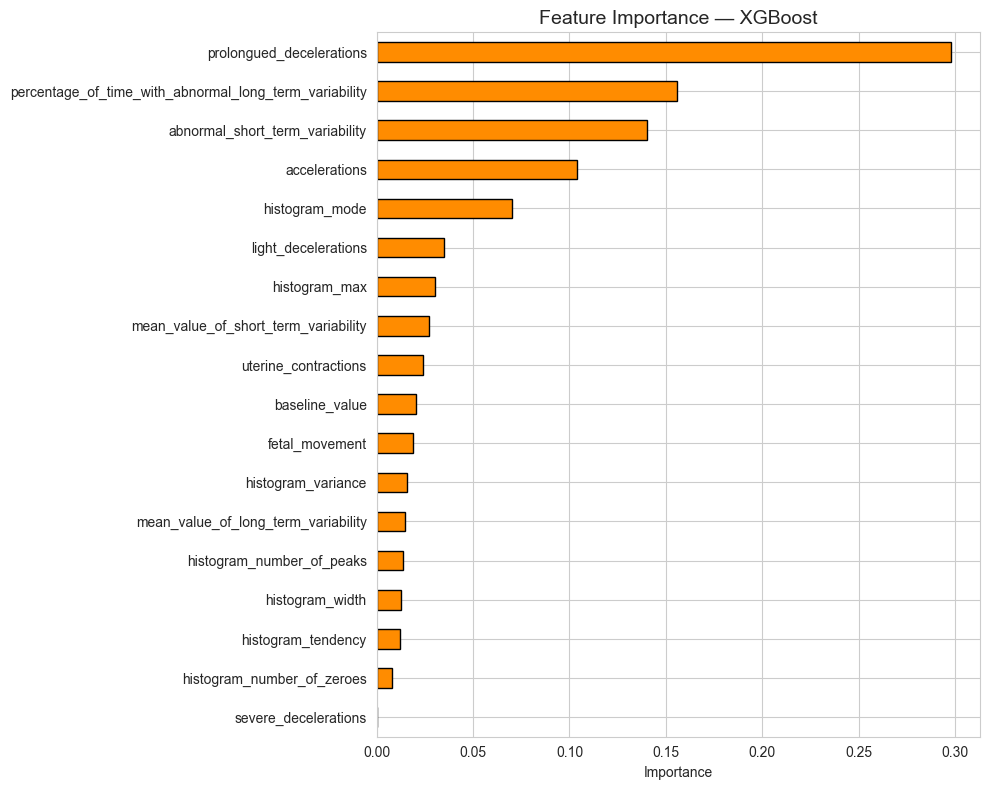


Top 5 najważniejszych cech (XGBoost):
  prolongued_decelerations: 0.2979
  percentage_of_time_with_abnormal_long_term_variability: 0.1558
  abnormal_short_term_variability: 0.1400
  accelerations: 0.1040
  histogram_mode: 0.0700


In [ ]:
importances_xgb = xgb_best.named_steps['model'].feature_importances_
feat_imp_xgb = pd.Series(importances_xgb, index=X_train_selected.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
feat_imp_xgb.plot(kind='barh', ax=ax, color='darkorange', edgecolor='black')
ax.set_title('Feature Importance — XGBoost', fontsize=14)
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nTop 5 najważniejszych cech (XGBoost):")
for feat, imp in feat_imp_xgb.sort_values(ascending=False).head(5).items():
    print(f"  {feat}: {imp:.4f}")

## 7. Ewaluacja i porównanie modeli

### Classification Report

In [33]:
target_names = ['1 - Normal', '2 - Suspect', '3 - Pathological']

print("=" * 60)
print("CLASSIFICATION REPORT — Random Forest")
print("=" * 60)
print(classification_report(y_test, y_pred_rf, target_names=target_names))

print("=" * 60)
print("CLASSIFICATION REPORT — XGBoost")
print("=" * 60)
print(classification_report(y_test, y_pred_xgb, target_names=target_names))

CLASSIFICATION REPORT — Random Forest
                  precision    recall  f1-score   support

      1 - Normal       0.97      0.96      0.96       332
     2 - Suspect       0.77      0.81      0.79        59
3 - Pathological       0.86      0.89      0.87        35

        accuracy                           0.93       426
       macro avg       0.87      0.89      0.88       426
    weighted avg       0.93      0.93      0.93       426

CLASSIFICATION REPORT — XGBoost
                  precision    recall  f1-score   support

      1 - Normal       0.97      0.98      0.97       332
     2 - Suspect       0.88      0.76      0.82        59
3 - Pathological       0.84      0.91      0.88        35

        accuracy                           0.95       426
       macro avg       0.90      0.89      0.89       426
    weighted avg       0.95      0.95      0.94       426



### Confusion Matrix

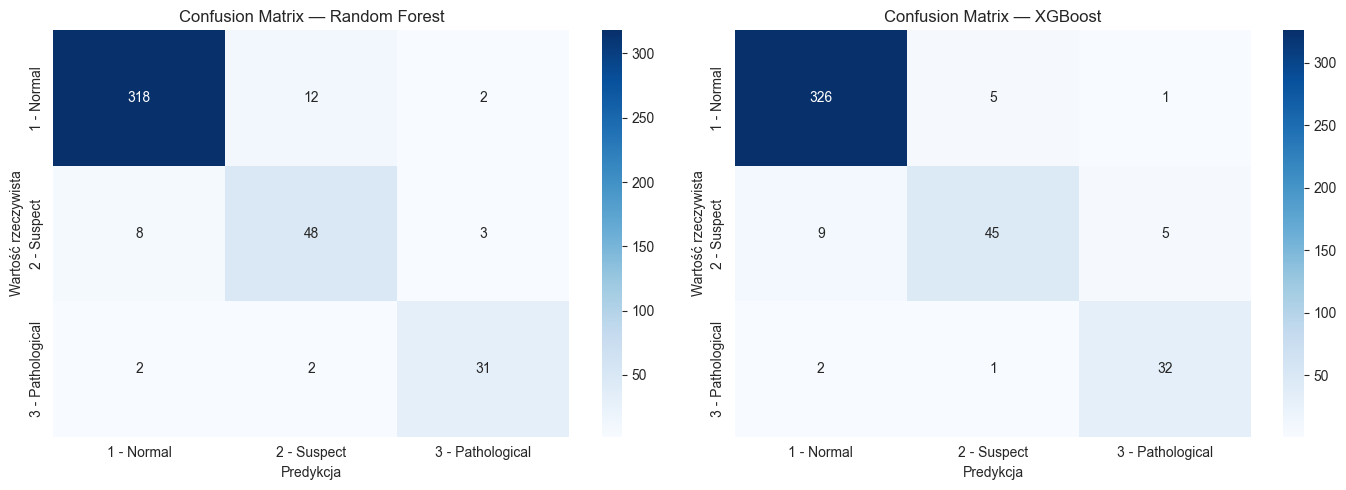

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in zip(axes, [y_pred_rf, y_pred_xgb], ['Random Forest', 'XGBoost']):
    cm = confusion_matrix(y_test, y_pred, labels=[1, 2, 3])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=target_names, yticklabels=target_names)
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12)
    ax.set_xlabel('Predykcja')
    ax.set_ylabel('Wartość rzeczywista')

plt.tight_layout()
plt.show()

### Tabela porównawcza metryk RF vs XGBoost

In [35]:
def compute_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (macro)': precision_score(y_true, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_true, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro'),
        'F1 - Normal': f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[0],
        'F1 - Suspect': f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[1],
        'F1 - Pathological': f1_score(y_true, y_pred, average=None, labels=[1, 2, 3])[2],
    }

metrics_rf = compute_metrics(y_test, y_pred_rf, 'Random Forest')
metrics_xgb = compute_metrics(y_test, y_pred_xgb, 'XGBoost')

comparison_df = pd.DataFrame([metrics_rf, metrics_xgb]).set_index('Model')
comparison_df = comparison_df.round(4)

print("Porównanie modeli na zbiorze testowym:")
comparison_df.T

Porównanie modeli na zbiorze testowym:


Model,Random Forest,XGBoost
Accuracy,0.9319,0.9460
Precision (macro),0.8683,0.8973
Recall (macro),0.8857,0.8863
F1 (macro),0.8768,0.8898
F1 - Normal,0.9636,0.9746
F1 - Suspect,0.7934,0.8182
F1 - Pathological,0.8732,0.8767


### Cross-validation (5-fold) — stabilność wyników

Cross-validation F1 (macro) — 5 foldów:
  Random Forest: 0.9771 ± 0.0050  [0.9748 0.9698 0.9761 0.9798 0.9849]
  XGBoost:       0.9826 ± 0.0031  [0.9786 0.9799 0.9874 0.9836 0.9836]


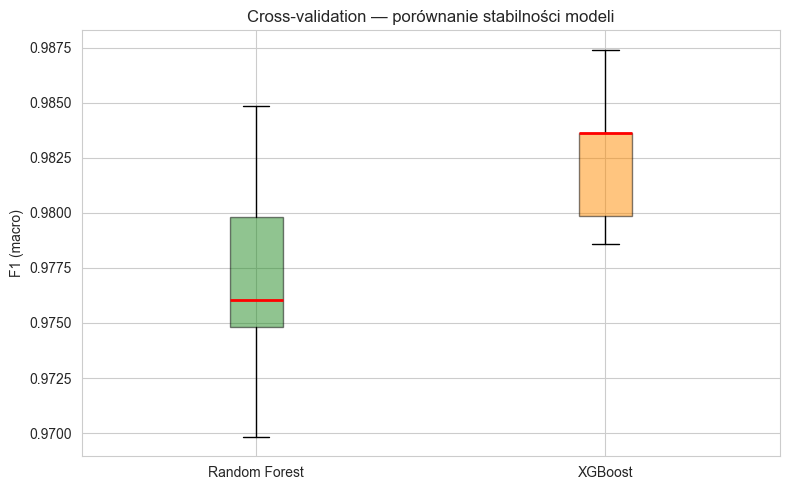

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rf = cross_val_score(rf_best, X_train_selected, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
cv_xgb = cross_val_score(xgb_best, X_train_selected, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

print("Cross-validation F1 (macro) — 5 foldów:")
print(f"  Random Forest: {cv_rf.mean():.4f} ± {cv_rf.std():.4f}  {cv_rf.round(4)}")
print(f"  XGBoost:       {cv_xgb.mean():.4f} ± {cv_xgb.std():.4f}  {cv_xgb.round(4)}")

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([cv_rf, cv_xgb], labels=['Random Forest', 'XGBoost'], patch_artist=True,
                boxprops=dict(facecolor='lightblue', edgecolor='black'),
                medianprops=dict(color='red', linewidth=2))
bp['boxes'][0].set_facecolor('forestgreen')
bp['boxes'][0].set_alpha(0.5)
bp['boxes'][1].set_facecolor('darkorange')
bp['boxes'][1].set_alpha(0.5)
ax.set_ylabel('F1 (macro)')
ax.set_title('Cross-validation — porównanie stabilności modeli', fontsize=12)
plt.tight_layout()
plt.show()

## 8. Podsumowanie i wnioski

In [37]:
print("=" * 60)
print("PODSUMOWANIE WYNIKÓW")
print("=" * 60)

print(f"\n{'Metryka':<25} {'Random Forest':>15} {'XGBoost':>15}")
print("-" * 55)
for col in comparison_df.columns:
    print(f"{col:<25} {comparison_df.loc['Random Forest', col]:>15.4f} {comparison_df.loc['XGBoost', col]:>15.4f}")

print(f"\n{'CV F1 (macro) mean':<25} {cv_rf.mean():>15.4f} {cv_xgb.mean():>15.4f}")
print(f"{'CV F1 (macro) std':<25} {cv_rf.std():>15.4f} {cv_xgb.std():>15.4f}")

better_model = 'Random Forest' if comparison_df.loc['Random Forest', 'F1 (macro)'] >= comparison_df.loc['XGBoost', 'F1 (macro)'] else 'XGBoost'
print(f"\n>>> Lepszy model wg F1 (macro) na zbiorze testowym: {better_model}")

PODSUMOWANIE WYNIKÓW

Metryka                     Random Forest         XGBoost
-------------------------------------------------------
Accuracy                           0.9319          0.9460
Precision (macro)                  0.8683          0.8973
Recall (macro)                     0.8857          0.8863
F1 (macro)                         0.8768          0.8898
F1 - Normal                        0.9636          0.9746
F1 - Suspect                       0.7934          0.8182
F1 - Pathological                  0.8732          0.8767

CV F1 (macro) mean                 0.9771          0.9826
CV F1 (macro) std                  0.0050          0.0031

>>> Lepszy model wg F1 (macro) na zbiorze testowym: XGBoost


### Interpretacja feature importance i wnioski

**Porównanie modeli:**
- Oba modele (Random Forest i XGBoost) są trenowane z użyciem **SMOTE wewnątrz pipeline**, więc zrównoważenie klas zachodzi wyłącznie na foldach treningowych i nie powoduje wycieku danych do walidacji.
- Główną metryką porównawczą jest **macro F1-score**, ponieważ uwzględnia ona niezbalansowanie klas — traktuje każdą klasę równoważnie.
- Cross-validation 5-fold pozwala ocenić stabilność modeli (niskie odchylenie standardowe = stabilny model).

**Najważniejsze cechy diagnostyczne:**
- W obu modelach wysoko pojawiają się cechy związane ze zmiennością rytmu serca płodu oraz deceleracjami, zwłaszcza **abnormal_short_term_variability**, **percentage_of_time_with_abnormal_long_term_variability**, **prolongued_decelerations**, **accelerations** i **histogram_mode**.
- **abnormal_short_term_variability** oraz **percentage_of_time_with_abnormal_long_term_variability** opisują zaburzenia zmienności FHR i są silnie związane z pogorszeniem dobrostanu płodu.
- **prolongued_decelerations** to jeden z najważniejszych sygnałów alarmowych w CTG, mogący wskazywać na niedotlenienie płodu.
- **accelerations** pomagają odróżnić zapis prawidłowy od podejrzanego lub patologicznego — ich obecność zwykle działa ochronnie diagnostycznie.
- **histogram_mode** odzwierciedla dominujący poziom częstości akcji serca i uzupełnia obraz ogólnego wzorca zapisu.

**Wpływ SMOTE:**
- Klasa Pathological stanowi zaledwie ~8% danych. Bez mechanizmu równoważenia model mógłby faworyzować klasę dominującą.
- SMOTE generuje syntetyczne próbki klas mniejszościowych wyłącznie na danych treningowych, co zwykle poprawia recall dla klas Suspect i Pathological.

**Ograniczenia i potencjalne usprawnienia:**
- SMOTE może generować nierealistyczne próbki syntetyczne — alternatywą byłby ADASYN lub `class_weight`/ważenie klas.
- Selekcja cech oparta na progu korelacji (>0.85) jest prosta — bardziej zaawansowane podejścia to Recursive Feature Elimination (RFE) lub regularyzacja.
- Zbiór jest stosunkowo mały (2126 rekordów) — wyniki mogą się różnić przy innych podziałach train/test.
- W praktyce klinicznej najważniejsza jest wysoka czułość (recall) dla klasy Pathological — nawet kosztem precision, aby nie przeoczyć zagrożonych płodów.